# 📄 Análisis de Recibos Peruanos
## Extracción de Datos Clave y Clasificación de Servicios

---
**Proyecto:** Aplicación de OCR y NLP para análisis automático de documentos en contexto peruano  
**Tipo de documento:** Recibos de servicios (luz, agua e internet)  
**Técnicas NLP:** Extracción de datos clave (empresa, RUC, fechas, monto, consumo) y clasificación del tipo de servicio

---


## 📦 Paso 1 — Instalación de Dependencias


In [1]:
!pip install -q easyocr
!pip install -q torch torchvision --index-url https://download.pytorch.org/whl/cpu
!pip install -q Pillow opencv-python-headless
!pip install -q nltk spacy
!pip install -q matplotlib
!pip install -q pymupdf
!python -m spacy download es_core_news_sm -q


print('✅ Dependencias instaladas')


✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
✅ Dependencias instaladas


## 📚 Paso 2 — Importaciones y Carga de Modelos


In [4]:
import os, re, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import easyocr
import nltk
import spacy
from PIL import Image

nltk.download('stopwords', quiet=True)
nltk.download('punkt',     quiet=True)
nltk.download('punkt_tab', quiet=True)
from nltk.corpus import stopwords
from nltk.tokenize import sent_tokenize

# Modelos
nlp_spacy  = spacy.load('es_core_news_sm')

print('✅ Librerías y modelos cargados')


✅ Librerías y modelos cargados


## Paso 3 — Recolección de Datos
Sube tus propios recibos de servicios peruanos (luz, agua e internet), como fotos o documentos escaneados.

Formatos soportados: JPG, PNG, WEBP, BMP y PDF (en PDF se usa la primera página).


Sube tus recibos (imágenes o PDFs):


Saving Agua-Cruces.jpeg to Agua-Cruces.jpeg
Saving Agua-Jesus.PDF to Agua-Jesus.PDF
Saving Luz-Huazo_dir1.jpeg to Luz-Huazo_dir1.jpeg
Saving Luz-Huazo_dir2.jpeg to Luz-Huazo_dir2.jpeg
Saving Luz-Jesus.jpeg to Luz-Jesus.jpeg
Saving recibo_ internet.jpeg to recibo_ internet (1).jpeg
Saving recibo_agua.jpeg to recibo_agua (1).jpeg
Saving recibo_luz.jpeg to recibo_luz (1).jpeg
  [1] Agua-Cruces.jpeg
  [2] Agua-Jesus.PDF
  [3] Luz-Huazo_dir1.jpeg
  [4] Luz-Huazo_dir2.jpeg
  [5] Luz-Jesus.jpeg
  [6] recibo_ internet (1).jpeg
  [7] recibo_agua (1).jpeg
  [8] recibo_luz (1).jpeg

✅ Total cargado: 8 recibos


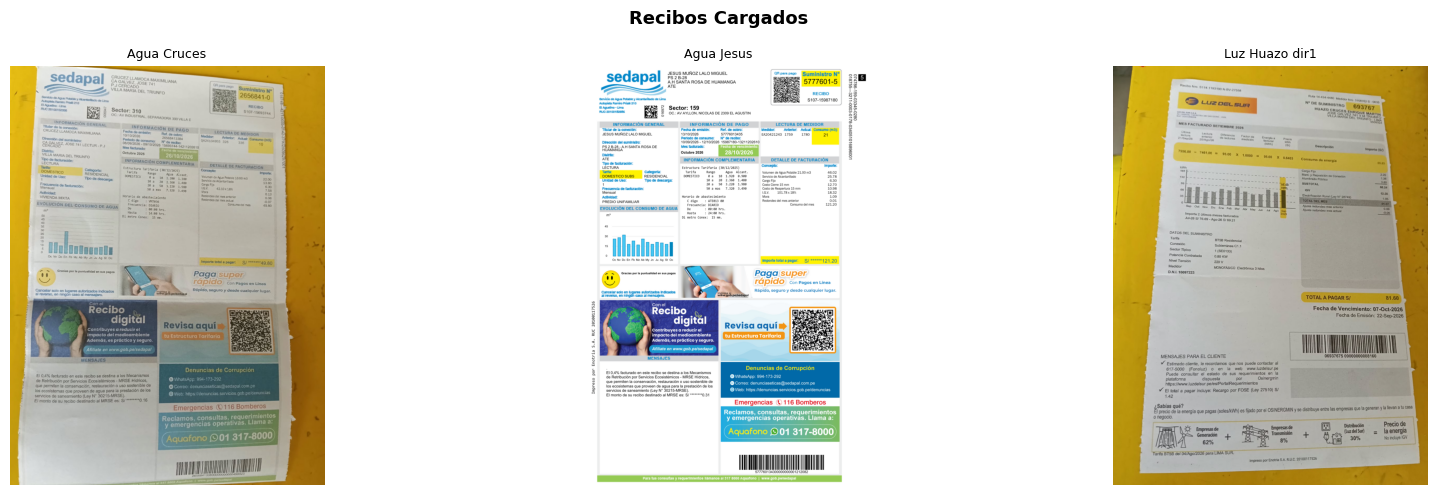

In [42]:
from google.colab import files
import fitz  # PyMuPDF

os.makedirs('imagenes_recibos', exist_ok=True)

def pdf_a_imagen(ruta_pdf, dpi=200):
    """Convierte la primera página del PDF en PNG."""
    doc = fitz.open(ruta_pdf)
    pix = doc[0].get_pixmap(dpi=dpi)
    ruta_png = os.path.splitext(ruta_pdf)[0] + '.png'
    pix.save(ruta_png)
    return ruta_png

print('Sube tus recibos (imágenes o PDFs):')
uploaded = files.upload()

DATASET, imagenes = [], []
for i, (nombre, contenido) in enumerate(uploaded.items(), start=1):
    ruta = f'imagenes_recibos/{nombre}'
    with open(ruta, 'wb') as f:
        f.write(contenido)
    if nombre.lower().endswith('.pdf'):
        ruta = pdf_a_imagen(ruta)          # desde aquí todo trabaja con la imagen
    imagenes.append(ruta)
    DATASET.append({
        'id':          i,
        'institucion': nombre.replace('_', ' ').replace('-', ' ').split('.')[0],
        'titulo':      f'recibo {i}',
        'ruta':        ruta
    })
    print(f'  [{i}] {nombre}')

print(f'\n✅ Total cargado: {len(imagenes)} recibos')

# Mostrar miniaturas
n = min(len(imagenes), 3)
fig, axes = plt.subplots(1, n, figsize=(6*n, 5))
if n == 1:
    axes = [axes]
for ax, ruta, d in zip(axes, imagenes[:n], DATASET[:n]):
    ax.imshow(Image.open(ruta))
    ax.set_title(d['institucion'], fontsize=9)
    ax.axis('off')
plt.suptitle('Recibos Cargados', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


## 🖼️ Paso 4 — Preprocesamiento de Imágenes

Aplicamos un pipeline de mejora para optimizar la extracción OCR:
escala de grises → eliminación de ruido → CLAHE → binarización Otsu.


Preprocesando Recibo 1...


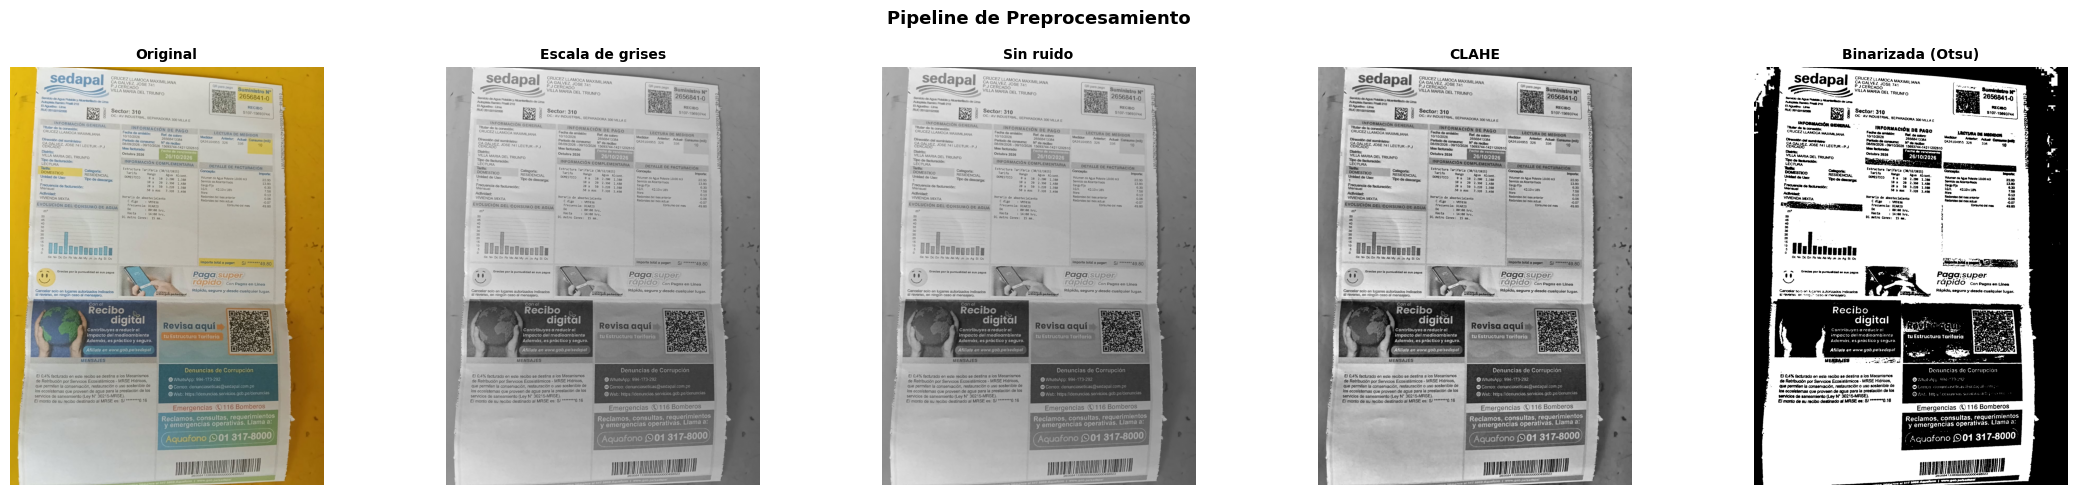

✅ Preprocesamiento completado


In [43]:
def preprocesar_imagen(ruta, mostrar=True, binarizar=False):
    img_bgr = cv2.imread(ruta)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    gris    = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    h, w    = gris.shape
    redim     = cv2.resize(gris, (int(w * 1.5), int(h * 1.5)), interpolation=cv2.INTER_CUBIC)
    sin_ruido = cv2.GaussianBlur(redim, (3, 3), 0)
    clahe_obj = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    contraste = clahe_obj.apply(sin_ruido)
    _, binarizada = cv2.threshold(contraste, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    if mostrar:
        pasos = [
            (img_rgb,    'Original',            None),
            (gris,       'Escala de grises',    'gray'),
            (sin_ruido,  'Sin ruido',            'gray'),
            (contraste,  'CLAHE',               'gray'),
            (binarizada, 'Binarizada (Otsu)',   'gray'),
        ]
        fig, axes = plt.subplots(1, 5, figsize=(22, 5))
        for ax, (img, titulo, cmap) in zip(axes, pasos):
            ax.imshow(img, cmap=cmap)
            ax.set_title(titulo, fontsize=10, fontweight='bold')
            ax.axis('off')
        plt.suptitle('Pipeline de Preprocesamiento', fontsize=13, fontweight='bold')
        plt.tight_layout()
        plt.show()

    return binarizada if binarizar else contraste

# Mostrar pipeline sobre el primer recibo
print('Preprocesando Recibo 1...')
preprocesar_imagen(imagenes[0])
print('✅ Preprocesamiento completado')


## 🔍 Paso 5 — Implementación del OCR con EasyOCR


In [44]:
print('Inicializando EasyOCR...')
reader = easyocr.Reader(['es', 'en'], gpu=False)
print('✅ EasyOCR listo')


Inicializando EasyOCR...
✅ EasyOCR listo


Procesando dataset...

[1/8] Agua Cruces...


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


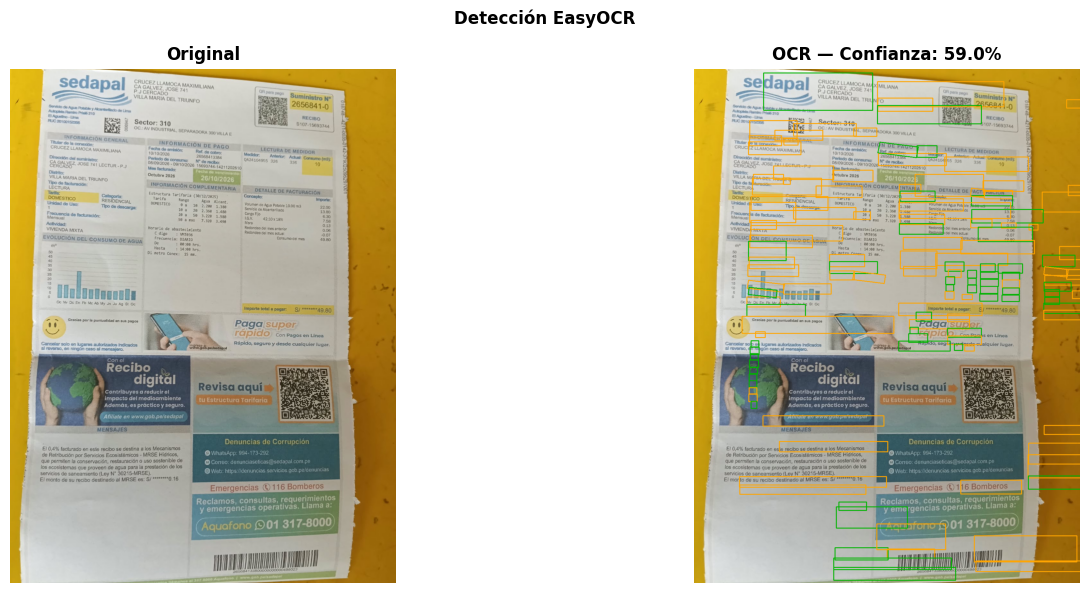

   Confianza: 59.0% | Chars: 2382
[2/8] Agua Jesus...
   Confianza: 73.4% | Chars: 2574
[3/8] Luz Huazo dir1...
   Confianza: 61.7% | Chars: 1665
[4/8] Luz Huazo dir2...
   Confianza: 56.5% | Chars: 1744
[5/8] Luz Jesus...
   Confianza: 62.2% | Chars: 1977
[6/8] recibo  internet (1)...
   Confianza: 59.5% | Chars: 603
[7/8] recibo agua (1)...
   Confianza: 66.3% | Chars: 1868
[8/8] recibo luz (1)...
   Confianza: 56.2% | Chars: 1287

📊 Confianza promedio: 61.8% | Min: 56.2% | Max: 73.4%


In [45]:
def extraer_texto_ocr(ruta, mostrar_boxes=True):
    img_bgr  = cv2.imread(ruta)
    img_rgb  = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    # Aplicar preprocesamiento antes de pasar a EasyOCR
    img_proc = preprocesar_imagen(ruta, mostrar=False)
    resultados = reader.readtext(img_proc, detail=1)
    texto      = ' '.join(r[1] for r in resultados)
    confianza  = float(np.mean([r[2] for r in resultados])) if resultados else 0.0

    if mostrar_boxes and resultados:
        img_boxes = img_rgb.copy()
        for bbox, _, conf in resultados:
            pts   = np.array(bbox, dtype=np.int32)
            color = (0, 180, 0) if conf > 0.7 else (255, 165, 0)
            cv2.polylines(img_boxes, [pts], True, color, 2)
        fig, axes = plt.subplots(1, 2, figsize=(16, 6))
        axes[0].imshow(img_rgb);   axes[0].set_title('Original',                         fontweight='bold'); axes[0].axis('off')
        axes[1].imshow(img_boxes); axes[1].set_title(f'OCR — Confianza: {confianza:.1%}', fontweight='bold'); axes[1].axis('off')
        plt.suptitle('Detección EasyOCR', fontsize=12, fontweight='bold')
        plt.tight_layout()
        plt.show()

    return texto, confianza


resultados_ocr = []
print('Procesando dataset...\n')
for doc in DATASET:
    print(f"[{doc['id']}/{len(DATASET)}] {doc['institucion']}...")
    texto, conf = extraer_texto_ocr(doc['ruta'], mostrar_boxes=(doc['id'] == 1))
    resultados_ocr.append({
        **doc,
        'texto_ocr': texto,
        'confianza': conf
    })
    print(f"   Confianza: {conf:.1%} | Chars: {len(texto)}")

confs = [r['confianza'] for r in resultados_ocr]
print(f'\n📊 Confianza promedio: {np.mean(confs):.1%} | Min: {np.min(confs):.1%} | Max: {np.max(confs):.1%}')


## 🧹 Paso 6 — Limpieza y Preprocesamiento del Texto

Normalizamos el texto OCR y aplicamos lematización con spaCy para obtener tokens clave.


In [46]:
CARACTERES_VALIDOS = r'[^a-záéíóúüñA-ZÁÉÍÓÚÜÑ0-9\s.,;:!?¿¡\-]'
STOP_ES            = set(stopwords.words('spanish'))

def normalizar(texto):
    texto = texto.replace('_', ' ').replace(';', '.')
    texto = re.sub(r'-\s+', '', texto)          # palabras partidas por guión
    texto = re.sub(CARACTERES_VALIDOS, ' ', texto)
    return re.sub(r'\s+', ' ', texto).strip()

def lematizar(texto_normalizado):
    tokens = [
        token.lemma_.lower()
        for token in nlp_spacy(texto_normalizado)
        if not token.is_stop
        and not token.is_punct
        and not token.is_space
        and len(token.text) > 2
    ]
    return ' '.join(tokens), tokens


print('🧹 Preprocesando textos...\n')
for r in resultados_ocr:
    normalizado      = normalizar(r['texto_ocr'])
    limpio, tokens   = lematizar(normalizado)
    r['texto_normalizado'] = normalizado
    r['texto_limpio']      = limpio
    r['tokens']            = tokens
    print(f"📄 {r['institucion']}")
    print(f"   Normalizado : {normalizado[:120]}...")
    print(f"   Lematizado  : {limpio[:120]}...")
    print(f"   Tokens clave: {len(tokens)}\n")

print('✅ Preprocesamiento completado')


🧹 Preprocesando textos...

📄 Agua Cruces
   Normalizado : sedapal SRISCEZEYAJSSCA MaxiMILIANA PJ CERCAD pan VILLAMARIA DEL TRIUNFO Suministro N Soa Ptnyhornoo Qun 2656841-0 9 Anr...
   Lematizado  : sedapal sriscezeyajssca maximiliana cercad pan villamaria triunfo suministro soa ptnyhornoo qun 2656841-0 anro pao 210 b...
   Tokens clave: 236

📄 Agua Jesus
   Normalizado : JESUS MUÑOZ LALO MIGUEL Capere pepo Suministro No sedapal PS 2 B-28 5 AH SANTA ROSA DE HUAMANGA 5777601-5 : ATE 1 RECIBO...
   Lematizado  : jesus muñoz lalo miguel capere pepo suministro sedapal b-28 santa rosa huamanga 5777601-5 ate recibo beivoode poooey noa...
   Tokens clave: 249

📄 Luz Huazo dir1
   Normalizado : 110J100 N nv 715a Haa 14 414 A40 LuzdELSUR N de buminibtro Munzo Cruces 893767 Ne Facturado Betiembre 2020 Ulia Loduro D...
   Lematizado  : 110j100 715a haa 414 a40 luzdelsur buminibtro munzo cruces 893767 facturado betiembre 2020 ulia loduro diteronan entenor...
   Tokens clave: 184

📄 Luz Huazo dir2


## 🤖 Paso 7 — NLP para recibos: clasificación + extracción de datos clave



In [47]:
EMPRESAS = {
    'luz':      ['luz del sur','pluz', 'enel', 'hidrandina', 'electronoroeste', 'electro oriente',
                 'electrocentro', 'seal', 'electro sur'],
    'agua':     ['sedapal', 'sedalib', 'epsel', 'sedacusco', 'seda ayacucho', 'emapa'],
    'internet': ['movistar', 'claro', 'entel', 'bitel', 'wow', 'win', 'telefonica', 'telefónica'],
}

PALABRAS_TIPO = {
    'luz':      ['kwh', 'energía', 'energia', 'eléctric', 'electric', 'osinergmin', 'potencia', 'suministro'],
    'agua':     ['m3', 'm³', 'alcantarillado', 'agua potable', 'sunass', 'sedapal', 'cargo fijo'],
    'internet': ['mbps', 'fibra', 'internet', 'megas', 'plan', 'router', 'telecomunicaciones'],
}

def clasificar_servicio(texto):
    t = texto.lower()
    puntos = {tipo: 0 for tipo in PALABRAS_TIPO}
    for tipo, empresas in EMPRESAS.items():
        puntos[tipo] += 3 * sum(e in t for e in empresas)      # la empresa pesa más
    for tipo, palabras in PALABRAS_TIPO.items():
        puntos[tipo] += sum(p in t for p in palabras)
    mejor = max(puntos, key=puntos.get)
    return mejor if puntos[mejor] > 0 else 'otro'

def detectar_empresa(texto):
    t = texto.lower()
    for tipo, empresas in EMPRESAS.items():
        for e in empresas:
            if re.search(rf'\b{re.escape(e)}\b', t):
                return e.title()
    return 'No detectada'

def a_numero(s):
    """Convierte '1,234.50' o '1.234,50' o '85,40' a float."""
    s = s.strip()
    ultimo = max(s.rfind('.'), s.rfind(','))
    if ultimo == -1:
        return float(s)
    entero = re.sub(r'[.,]', '', s[:ultimo])
    return float(f'{entero}.{s[ultimo+1:]}')

def extraer_ruc(texto):
    m = re.search(r'RUC\W{0,10}(\d{11})', texto, re.IGNORECASE)
    if m:
        return m.group(1)
    m = re.search(r'\b((?:10|20)\d{9})\b', texto)
    return m.group(1) if m else 'No detectado'

def extraer_fechas(texto):
    numericas = re.findall(r'\b\d{1,2}[/\-.]\d{1,2}[/\-.]\d{2,4}\b', texto)
    escritas  = re.findall(r'\b\d{1,2}\s+de\s+[a-záéíóú]+\s+(?:de\s+)?\d{4}\b', texto, re.IGNORECASE)
    return numericas + escritas

def extraer_monto_total(texto):
    # se prueba por prioridad: "total a pagar" primero
    for clave in [r'total\s*a\s*pagar', r'importe\s*total', r'monto\s*total']:
        m = re.search(clave + r'.{0,60}?(\d{1,3}(?:[.,]\d{3})*[.,]\d{2})', texto, re.IGNORECASE)
        if m:
            return a_numero(m.group(1))
    montos = re.findall(r'\d{1,3}(?:[.,]\d{3})*[.,]\d{2}\b', texto)
    return max(a_numero(x) for x in montos) if montos else None

def extraer_fechas(texto):
    numericas = re.findall(r'\b\d{1,2}[/\-.]\d{1,2}[/\-.]\d{2,4}\b', texto)
    con_mes   = re.findall(r'\b[\dOo]{1,2}[/\-.][A-Za-z0]{3}[/\-.]\d{4}\b', texto)
    escritas  = re.findall(r'\b\d{1,2}\s+de\s+[a-záéíóú]+\s+(?:de\s+)?\d{4}\b', texto, re.IGNORECASE)
    return numericas + con_mes + escritas

def extraer_consumo(texto):
    m = re.search(r'(?<![\d.,])([1-9]\d*(?:[.,]\d+)?)\s*(kwh|m3|m³|mbps)', texto, re.IGNORECASE)
    return f"{m.group(1)} {m.group(2).lower()}" if m else 'No detectado'

def analizar_recibo(texto_ocr):
    return {
        'tipo_servicio': clasificar_servicio(texto_ocr),
        'empresa':       detectar_empresa(texto_ocr),
        'ruc':           extraer_ruc(texto_ocr),
        'fechas':        extraer_fechas(texto_ocr),
        'monto_total':   extraer_monto_total(texto_ocr),
        'consumo':       extraer_consumo(texto_ocr),
    }

print('🔎 Analizando recibos...\n')
for r in resultados_ocr:
    r['analisis'] = analizar_recibo(r['texto_ocr'])   # se usa el texto original para no perder S/, puntos ni números
    a = r['analisis']
    print(f"📄 {r['institucion']}")
    print(f"   Servicio : {a['tipo_servicio']}")
    print(f"   Empresa  : {a['empresa']}")
    print(f"   RUC      : {a['ruc']}")
    print(f"   Fechas   : {a['fechas'][:3]}")
    print(f"   Monto    : S/ {a['monto_total']}")
    print(f"   Consumo  : {a['consumo']}\n")

🔎 Analizando recibos...

📄 Agua Cruces
   Servicio : agua
   Empresa  : Sedapal
   RUC      : No detectado
   Fechas   : ['10/10/2026', '26/10/2026', '30/12/2025']
   Monto    : S/ 49.8
   Consumo  : 1000 m3

📄 Agua Jesus
   Servicio : agua
   Empresa  : Sedapal
   RUC      : No detectado
   Fechas   : ['13/10/2026', '10/09/2026', '12/10/2026']
   Monto    : S/ 121.2
   Consumo  : 2100 m3

📄 Luz Huazo dir1
   Servicio : luz
   Empresa  : No detectada
   RUC      : 20100117526
   Fechas   : ['07-Oct-2026', '22-Sep-2026']
   Monto    : S/ 81.6
   Consumo  : 22 kwh

📄 Luz Huazo dir2
   Servicio : luz
   Empresa  : No detectada
   RUC      : 20100117526
   Fechas   : ['07-Oct-2026', '22-Sep-2026']
   Monto    : S/ 171.3
   Consumo  : 197.00 kwh

📄 Luz Jesus
   Servicio : luz
   Empresa  : No detectada
   RUC      : 20100117526
   Fechas   : ['03-Sep-2026', '19-Ago-2026', '10-Sep-2026']
   Monto    : S/ 519.6
   Consumo  : 26 kwh

📄 recibo  internet (1)
   Servicio : internet
   Empresa  : 

## 📊 Paso 8 — Visualizaciones


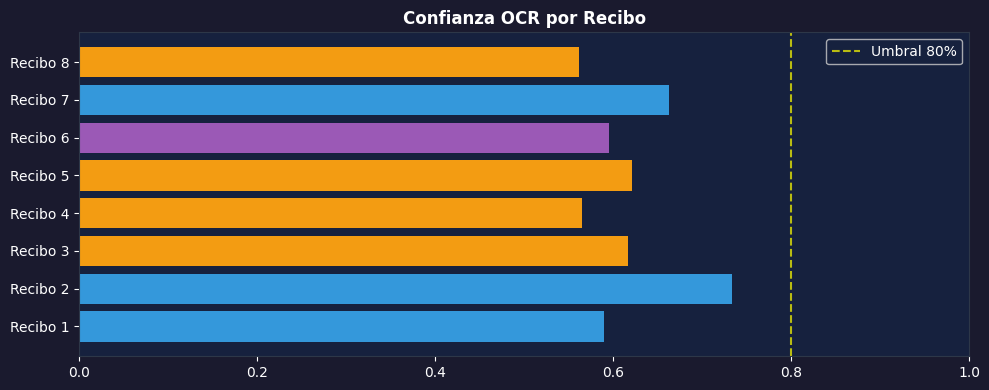

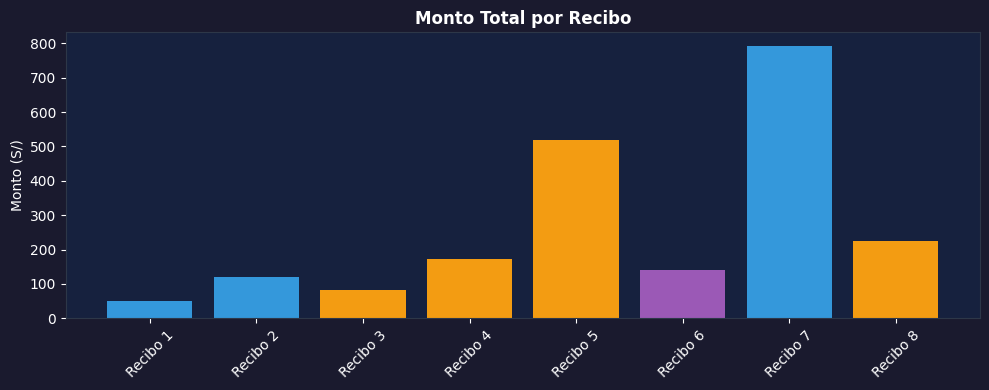

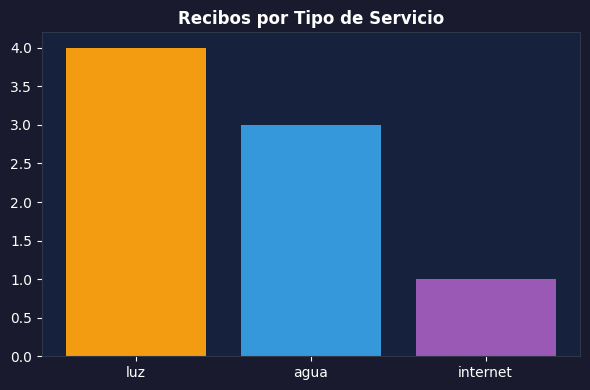

In [48]:
COLORS = {'luz': '#F39C12', 'agua': '#3498DB', 'internet': '#9B59B6', 'otro': '#7F8C8D'}

def estilo_ax(ax):
    ax.set_facecolor('#16213e')
    ax.tick_params(colors='white')
    ax.xaxis.label.set_color('white')
    ax.yaxis.label.set_color('white')
    for spine in ax.spines.values():
        spine.set_edgecolor('#2d3748')

ids     = [f"Recibo {r['id']}" for r in resultados_ocr]
confs   = [r['confianza'] for r in resultados_ocr]
tipos   = [r['analisis']['tipo_servicio'] for r in resultados_ocr]
montos  = [r['analisis']['monto_total'] or 0 for r in resultados_ocr]
colores = [COLORS[t] for t in tipos]

# — Gráfico 1: Confianza OCR —
fig, ax = plt.subplots(figsize=(10, 4))
fig.patch.set_facecolor('#1a1a2e')
estilo_ax(ax)
ax.barh(ids, confs, color=colores)
ax.axvline(0.8, color='yellow', linestyle='--', alpha=0.7, label='Umbral 80%')
ax.set_xlim(0, 1)
ax.set_title('Confianza OCR por Recibo', color='white', fontweight='bold')
ax.legend(facecolor='#16213e', labelcolor='white')
plt.tight_layout()
plt.show()

# — Gráfico 2: Monto total por recibo —
fig, ax = plt.subplots(figsize=(10, 4))
fig.patch.set_facecolor('#1a1a2e')
estilo_ax(ax)
ax.bar(ids, montos, color=colores)
ax.set_ylabel('Monto (S/)')
ax.set_title('Monto Total por Recibo', color='white', fontweight='bold')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# — Gráfico 3: Cantidad de recibos por tipo de servicio —
conteo = pd.Series(tipos).value_counts()
fig, ax = plt.subplots(figsize=(6, 4))
fig.patch.set_facecolor('#1a1a2e')
estilo_ax(ax)
ax.bar(conteo.index, conteo.values, color=[COLORS[t] for t in conteo.index])
ax.set_title('Recibos por Tipo de Servicio', color='white', fontweight='bold')
plt.tight_layout()
plt.show()


## 💾 Paso 9 — Exportar Resultados


In [49]:
registros = [
    {
        'id':                  r['id'],
        'archivo':             r['institucion'],
        'tipo_servicio':       r['analisis']['tipo_servicio'],
        'empresa':             r['analisis']['empresa'],
        'ruc':                 r['analisis']['ruc'],
        'fechas':              ' | '.join(r['analisis']['fechas']),
        'monto_total':         r['analisis']['monto_total'],
        'consumo':             r['analisis']['consumo'],
        'palabras_originales': len(r['texto_ocr'].split()),
        'confianza_ocr':       round(r['confianza'], 4),
    }
    for r in resultados_ocr
]

df = pd.DataFrame(registros)
df.to_csv('resultados_nlp_recibos.csv', index=False, encoding='utf-8-sig')
print('✅ CSV  → resultados_nlp_recibos.csv')

with open('resultados_nlp_recibos.json', 'w', encoding='utf-8') as f:
    json.dump(resultados_ocr, f, ensure_ascii=False, indent=2, default=str)
print('✅ JSON → resultados_nlp_recibos.json')

print('\n📋 TABLA DE RESULTADOS:')
display(df[['id', 'archivo', 'tipo_servicio', 'empresa', 'monto_total', 'confianza_ocr']])

✅ CSV  → resultados_nlp_recibos.csv
✅ JSON → resultados_nlp_recibos.json

📋 TABLA DE RESULTADOS:


,id,archivo,tipo_servicio,empresa,monto_total,confianza_ocr
0,1,Agua Cruces,agua,Sedapal,49.8,0.5902
1,2,Agua Jesus,agua,Sedapal,121.2,0.7341
2,3,Luz Huazo dir1,luz,No detectada,81.6,0.6170
3,4,Luz Huazo dir2,luz,No detectada,171.3,0.5654
4,5,Luz Jesus,luz,No detectada,519.6,0.6216
5,6,recibo internet (1),internet,Win,139.0,0.5948
6,7,recibo agua (1),agua,Sedapal,792.7,0.6627
7,8,recibo luz (1),luz,Pluz,224.5,0.5619


## Paso 10 — Aplicación en Streamlit
La aplicación web permite cargar recibos (imagen o PDF), ver el texto extraído y limpio, mostrar el análisis NLP y descargar los resultados en CSV y JSON.

El código se guarda en `app.py` y las librerías en `requirements.txt`, listos para subir al repositorio de GitHub y desplegar.

### 10A — Código de la app (app.py)

In [50]:
%%writefile app.py
import re, json
import cv2, fitz, nltk, easyocr
import numpy as np
import pandas as pd
import streamlit as st
from nltk.corpus import stopwords

st.set_page_config(page_title="Análisis de Recibos Peruanos", page_icon="📄", layout="wide")

# ---------- Modelos (se cargan una sola vez) ----------
@st.cache_resource
def cargar_modelos():
    nltk.download('stopwords', quiet=True)
    return easyocr.Reader(['es'], gpu=False), set(stopwords.words('spanish'))

reader, STOP_ES = cargar_modelos()

# ---------- Carga y preprocesamiento ----------
def cargar_imagen(archivo):
    datos = archivo.read()
    if archivo.name.lower().endswith('.pdf'):
        pix = fitz.open(stream=datos, filetype='pdf')[0].get_pixmap(dpi=200)
        img = np.frombuffer(pix.samples, np.uint8).reshape(pix.height, pix.width, pix.n)
        return cv2.cvtColor(img, cv2.COLOR_RGB2BGR if pix.n == 3 else cv2.COLOR_RGBA2BGR)
    return cv2.imdecode(np.frombuffer(datos, np.uint8), cv2.IMREAD_COLOR)

def preprocesar(img_bgr):
    h, w = img_bgr.shape[:2]
    escala = 1600 / max(h, w)                                   # redimensionamiento
    img = cv2.resize(img_bgr, None, fx=escala, fy=escala, interpolation=cv2.INTER_CUBIC)
    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)                # escala de grises
    gris = cv2.fastNlMeansDenoising(gris, None, 10, 7, 21)      # eliminar ruido
    gris = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gris)   # contraste
    return gris

# ---------- OCR y limpieza ----------
def hacer_ocr(img_proc):
    res = reader.readtext(img_proc, detail=1)
    texto = ' '.join(r[1] for r in res)
    conf = float(np.mean([r[2] for r in res])) if res else 0.0
    return texto, conf

def limpiar_texto(texto):
    t = re.sub(r'[^a-záéíóúüñA-ZÁÉÍÓÚÜÑ0-9\s.,\-]', ' ', texto)
    t = re.sub(r'\s+', ' ', t).strip().lower()
    tokens = [w for w in re.findall(r'[a-záéíóúüñ0-9]+', t) if w not in STOP_ES and len(w) > 2]
    return t, ' '.join(tokens)

# ---------- NLP (igual que el Paso 7 del notebook) ----------
EMPRESAS = {
    'luz':      ['luz del sur','pluz', 'enel', 'hidrandina', 'electronoroeste', 'electro oriente',
                 'electrocentro', 'seal', 'electro sur'],
    'agua':     ['sedapal', 'sedalib', 'epsel', 'sedacusco', 'seda ayacucho', 'emapa'],
    'internet': ['movistar', 'claro', 'entel', 'bitel', 'wow', 'win', 'telefonica', 'telefónica'],
}
PALABRAS_TIPO = {
    'luz':      ['kwh', 'energía', 'energia', 'eléctric', 'electric', 'osinergmin', 'potencia', 'suministro'],
    'agua':     ['m3', 'm³', 'alcantarillado', 'agua potable', 'sunass', 'sedapal', 'cargo fijo'],
    'internet': ['mbps', 'fibra', 'internet', 'megas', 'plan', 'router', 'telecomunicaciones'],
}

def clasificar_servicio(texto):
    t = texto.lower()
    puntos = {k: 0 for k in PALABRAS_TIPO}
    for tipo, empresas in EMPRESAS.items():
        puntos[tipo] += 3 * sum(e in t for e in empresas)
    for tipo, palabras in PALABRAS_TIPO.items():
        puntos[tipo] += sum(p in t for p in palabras)
    mejor = max(puntos, key=puntos.get)
    return mejor if puntos[mejor] > 0 else 'otro'

def detectar_empresa(texto):
    t = texto.lower()
    for empresas in EMPRESAS.values():
        for e in empresas:
            if re.search(rf'\b{re.escape(e)}\b', t):
                return e.title()
    return 'No detectada'

def a_numero(s):
    s = s.strip()
    ultimo = max(s.rfind('.'), s.rfind(','))
    if ultimo == -1:
        return float(s)
    return float(f"{re.sub(r'[.,]', '', s[:ultimo])}.{s[ultimo+1:]}")

def extraer_ruc(texto):
    m = re.search(r'RUC\W{0,10}(\d{11})', texto, re.IGNORECASE) or re.search(r'\b((?:10|20)\d{9})\b', texto)
    return m.group(1) if m else 'No detectado'

def extraer_monto_total(texto):
    # se prueba por prioridad: "total a pagar" primero
    for clave in [r'total\s*a\s*pagar', r'importe\s*total', r'monto\s*total']:
        m = re.search(clave + r'.{0,60}?(\d{1,3}(?:[.,]\d{3})*[.,]\d{2})', texto, re.IGNORECASE)
        if m:
            return a_numero(m.group(1))
    montos = re.findall(r'\d{1,3}(?:[.,]\d{3})*[.,]\d{2}\b', texto)
    return max(a_numero(x) for x in montos) if montos else None

def extraer_fechas(texto):
    numericas = re.findall(r'\b\d{1,2}[/\-.]\d{1,2}[/\-.]\d{2,4}\b', texto)
    con_mes   = re.findall(r'\b[\dOo]{1,2}[/\-.][A-Za-z0]{3}[/\-.]\d{4}\b', texto)
    escritas  = re.findall(r'\b\d{1,2}\s+de\s+[a-záéíóú]+\s+(?:de\s+)?\d{4}\b', texto, re.IGNORECASE)
    return numericas + con_mes + escritas

def extraer_consumo(texto):
    m = re.search(r'(?<![\d.,])([1-9]\d*(?:[.,]\d+)?)\s*(kwh|m3|m³|mbps)', texto, re.IGNORECASE)
    return f"{m.group(1)} {m.group(2).lower()}" if m else 'No detectado'

def analizar_recibo(texto):
    return {'tipo_servicio': clasificar_servicio(texto), 'empresa': detectar_empresa(texto),
            'ruc': extraer_ruc(texto), 'fechas': extraer_fechas(texto),
            'monto_total': extraer_monto_total(texto), 'consumo': extraer_consumo(texto)}

# ---------- Interfaz ----------
st.title("📄 Análisis de Recibos Peruanos")
st.write("Sube recibos de luz, agua o internet (imagen o PDF) y obtén sus datos clave.")

archivos = st.file_uploader("Sube tus recibos", type=['jpg', 'jpeg', 'png', 'webp', 'bmp', 'pdf'],
                            accept_multiple_files=True)
registros, detalle = [], []

for archivo in archivos or []:
    with st.expander(f"📄 {archivo.name}", expanded=True):
        with st.spinner("Procesando..."):
            img = cargar_imagen(archivo)
            proc = preprocesar(img)
            texto, conf = hacer_ocr(proc)
            normalizado, limpio = limpiar_texto(texto)
            a = analizar_recibo(texto)

        c1, c2 = st.columns(2)
        c1.image(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), caption="Original", use_container_width=True)
        c2.image(proc, caption="Preprocesada", use_container_width=True)

        st.subheader("Texto extraído")
        st.text_area("OCR", texto, height=150, key=f"ocr_{archivo.name}")
        st.subheader("Texto limpio")
        st.text_area("Limpio", limpio, height=100, key=f"limpio_{archivo.name}")

        st.subheader("Resultado del análisis")
        m1, m2, m3, m4 = st.columns(4)
        m1.metric("Servicio", a['tipo_servicio'].title())
        m2.metric("Empresa", a['empresa'])
        m3.metric("Monto total", f"S/ {a['monto_total']}" if a['monto_total'] else "No detectado")
        m4.metric("Confianza OCR", f"{conf:.0%}")
        st.write(f"**RUC:** {a['ruc']}  |  **Consumo:** {a['consumo']}  |  **Fechas:** {', '.join(a['fechas'][:3]) or 'No detectadas'}")

    registros.append({'archivo': archivo.name, 'tipo_servicio': a['tipo_servicio'], 'empresa': a['empresa'],
                      'ruc': a['ruc'], 'fechas': ' | '.join(a['fechas']), 'monto_total': a['monto_total'],
                      'consumo': a['consumo'], 'confianza_ocr': round(conf, 4)})
    detalle.append({'archivo': archivo.name, 'texto_ocr': texto, 'texto_limpio': limpio, 'analisis': a})

if registros:
    st.divider()
    st.subheader("📋 Resumen de todos los recibos")
    df = pd.DataFrame(registros)
    st.dataframe(df, use_container_width=True)
    d1, d2 = st.columns(2)
    d1.download_button("⬇️ Descargar CSV", df.to_csv(index=False).encode('utf-8-sig'),
                       "resultados_recibos.csv", "text/csv")
    d2.download_button("⬇️ Descargar JSON", json.dumps(detalle, ensure_ascii=False, indent=2, default=str),
                       "resultados_recibos.json", "application/json")

Overwriting app.py


### 10B — Librerías necesarias (requirements.txt)

In [51]:
%%writefile requirements.txt
--extra-index-url https://download.pytorch.org/whl/cpu
torch
streamlit==1.40.2
easyocr
opencv-python-headless
pymupdf
pandas
numpy
nltk

Overwriting requirements.txt


### 10C — Descargar archivos para GitHub

In [52]:
from google.colab import files
files.download('app.py')
files.download('requirements.txt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>